# Miniproyecto 1: Clasificación de MRI con Redes Neuronales Convolucionales para Tipos de Cáncer Cerebral

**Universidad de los Andes — Maestría en Inteligencia Artificial (MAIA)**  
**Curso:** Técnicas de Deep Learning (MAIA-4213)

### Autores
| Nombre Completo | Correo Electrónico | Código |
| :--- | :--- | :--- |
| **Otto Wilmer Castillo Santacruz** | `o.castillos@uniandes.edu.co` | 202611101 |
| **Edgar Andrés Pérez Mora** | `ea.perezm1@uniandes.edu.co` | 200822340 |
| **Silvio Yopasa Romero** | `s.yopasa@uniandes.edu.co` | 202615521 |

---

## Contexto
La resonancia magnética (MRI) desempeña un papel fundamental en la detección y clasificación de los diferentes tipos de cáncer cerebral. La aplicación de redes neuronales convolucionales (CNN) ha incrementado notablemente la precisión en la interpretación de estos volúmenes, al ser entrenadas para reconocer patrones y características distintivas asociadas a cada tipo de tumor. Las resonancias magnéticas (MRI) generan volúmenes tridimensionales compuestos por múltiples capas, donde cada una corresponde a una imagen bidimensional del tejido analizado.

Procesar un volumen completo implica manejar una gran cantidad de datos simultáneamente, lo que resulta computacionalmente costoso y demanda considerables recursos de tiempo y memoria. En este trabajo se emplean exclusivamente imágenes individuales extraídas de las capas de los estudios MRI, en lugar de procesar el volumen tridimensional completo. Esta estrategia transforma el problema en una tarea de clasificación supervisada de imágenes bidimensionales, reduciendo significativamente la carga computacional.

### A. Objetivo
- Desarrollar un método basado en redes neuronales convolucionales que permita clasificar con exactitud imágenes extraídas de estudios MRI en una de las 4 categorías diagnósticas (`glioma`, `meningioma`, `notumor`, `pituitary`).

### B. Conjunto de Datos
- El conjunto de datos comprende $7\,023$ imágenes bidimensionales extraídas de resonancias magnéticas cerebrales adquiridas desde distintos planos anatómicos y disponibles en el dominio público.

---
## 0. Configuración del Entorno e Importación de Librerías
Se importan las librerías requeridas para el procesamiento de imágenes, la manipulación de tensores, el entrenamiento de modelos en PyTorch y el cálculo de métricas de desempeño. Asimismo, se fijan las semillas pseudoaleatorias para garantizar la reproducibilidad experimental y se configura el dispositivo de aceleración por hardware (`cuda`, `mps` o `cpu`).

In [1]:
from pathlib import Path
import pandas as pd


---
## 1. Preparación de las Imágenes para el Entrenamiento y Prueba del Modelo
En esta etapa se estructura el flujo de ingestión, exploración y preprocesamiento de las imágenes de resonancia magnética, garantizando una separación estratificada en subconjuntos de entrenamiento, validación y prueba.

### 1.1. Carga e Indexación del Conjunto de Datos
Se define la ruta de almacenamiento del conjunto de datos, se establecen las 4 categorías diagnósticas (`glioma`, `meningioma`, `notumor`, `pituitary`) y se construye un registro tabular con las rutas de las $7\,023$ imágenes junto con su codificación numérica correspondiente.

In [2]:


CLASSES = ["glioma", "meningioma", "healthy", "pituitary"]
CLASS_TO_IDX = {cls_name: idx for idx, cls_name in enumerate(CLASSES)}
IDX_TO_CLASS = {idx: cls_name for idx, cls_name in enumerate(CLASSES)}

DATA_DIR = Path("./data/brain-tumor-mri-scans")

def collect_image_paths(root_dir: Path, classes: list) -> pd.DataFrame:
    records = []
    
    for file_path in root_dir.rglob("*"):
        if file_path.is_file():
            parent_name = file_path.parent.name.lower()
            for cls_name in classes:
                if cls_name in parent_name:
                    records.append({
                        "filepath": str(file_path.resolve()),
                        "label_name": cls_name,
                        "label": CLASS_TO_IDX[cls_name]
                    })
                    break
    return pd.DataFrame(records)

df_images = collect_image_paths(DATA_DIR, CLASSES)
print(f"Total de imágenes indexadas: {len(df_images)}")
display(df_images.head())

df_images["label_name"].value_counts()

Total de imágenes indexadas: 7023


,filepath,label_name,label
0,/Users/ottocastillo/Documents/workspace/TDL_Mi...,pituitary,3
1,/Users/ottocastillo/Documents/workspace/TDL_Mi...,pituitary,3
2,/Users/ottocastillo/Documents/workspace/TDL_Mi...,pituitary,3
3,/Users/ottocastillo/Documents/workspace/TDL_Mi...,pituitary,3
4,/Users/ottocastillo/Documents/workspace/TDL_Mi...,pituitary,3


label_name
healthy       2000
pituitary     1757
meningioma    1645
glioma        1621
Name: count, dtype: int64

### 1.2. Análisis Exploratorio de Datos (EDA)
En primer lugar, se identifican y eliminan las imágenes duplicadas, de modo que todas las estadísticas posteriores describan exactamente el conjunto que se empleará para entrenar y evaluar el modelo. Sobre el conjunto depurado se analiza la distribución de frecuencias absolutas y relativas por categoría diagnóstica con el propósito de identificar posibles desbalances de clase. Adicionalmente, se inspeccionan las dimensiones espaciales de los cortes, se visualiza una muestra representativa de cada clase y se cuantifican los marcos claros presentes en el borde de algunas imágenes.

#### 1.2.1. Eliminación de imágenes duplicadas
Se calcula el hash MD5 del contenido de cada archivo para identificar imágenes idénticas. Se conserva una sola copia por grupo y se descartan por completo los grupos cuyas copias tengan etiquetas contradictorias. El `DataFrame` resultante (`df_clean`) es la base para el resto del EDA, la partición (1.3) y el *pipeline* de transformaciones (1.4).

In [3]:
# Detección y eliminación de imágenes duplicadas mediante el hash MD5 del contenido
import hashlib

def file_md5(filepath: str) -> str:
    return hashlib.md5(Path(filepath).read_bytes()).hexdigest()

df_images["md5"] = df_images["filepath"].map(file_md5)
dup_groups = df_images[df_images.duplicated("md5", keep=False)].groupby("md5")
conflicting_md5 = dup_groups["label_name"].nunique().loc[lambda s: s > 1].index

print(f"Grupos de imágenes idénticas: {dup_groups.ngroups}")
print(f"Copias redundantes a eliminar: {df_images.duplicated('md5').sum()}")
print(f"Grupos con etiquetas contradictorias entre copias: {len(conflicting_md5)}")

# Se conserva una sola copia por grupo; los grupos con etiquetas contradictorias se descartan por completo
df_clean = (df_images[~df_images["md5"].isin(conflicting_md5)]
            .sort_values("filepath")
            .drop_duplicates("md5", keep="first")
            .reset_index(drop=True))

df_dedup_summary = pd.DataFrame({
    "antes": df_images["label_name"].value_counts(),
    "despues": df_clean["label_name"].value_counts(),
}).reindex(CLASSES)
df_dedup_summary["eliminadas"] = df_dedup_summary["antes"] - df_dedup_summary["despues"]
df_dedup_summary["despues_%"] = (df_dedup_summary["despues"] / df_dedup_summary["despues"].sum() * 100).round(2)
display(df_dedup_summary)

print(f"Total de imágenes únicas: {len(df_clean)}")

Grupos de imágenes idénticas: 300
Copias redundantes a eliminar: 426
Grupos con etiquetas contradictorias entre copias: 0


,antes,despues,eliminadas,despues_%
label_name,,,,
glioma,1621,1620,1,24.56
meningioma,1645,1531,114,23.21
healthy,2000,1706,294,25.86
pituitary,1757,1740,17,26.38


Total de imágenes únicas: 6597


#### 1.2.2. Distribución de frecuencias absolutas y relativas por categoría diagnóstica
Se cuantifica el número de imágenes por categoría diagnóstica en el conjunto depurado, tanto en valores absolutos como en porcentaje, y se calcula la razón de desbalance (clase mayoritaria / minoritaria). El gráfico de barras compara cada clase con la media por categoría para identificar visualmente posibles desbalances.

,frecuencia_absoluta,frecuencia_relativa_%
label_name,,
glioma,1620,24.56
meningioma,1531,23.21
healthy,1706,25.86
pituitary,1740,26.38


Razón de desbalance (clase mayoritaria / minoritaria): 1.14


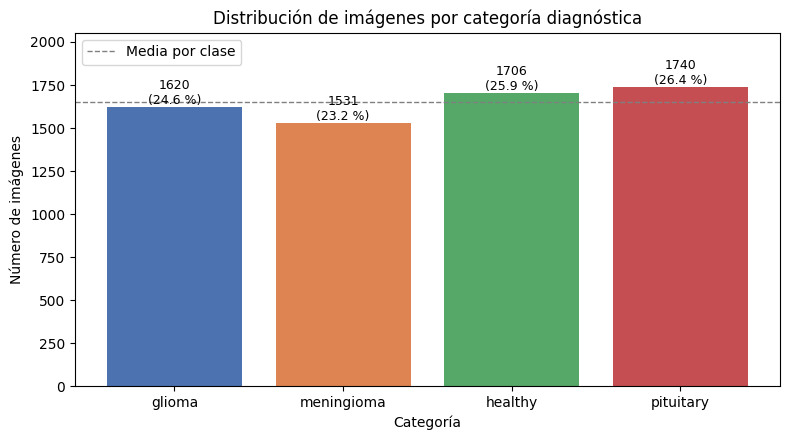

In [4]:
# Distribución de frecuencias absolutas y relativas por categoría diagnóstica
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

class_counts = df_clean["label_name"].value_counts().reindex(CLASSES)
df_distribution = pd.DataFrame({
    "frecuencia_absoluta": class_counts,
    "frecuencia_relativa_%": (class_counts / class_counts.sum() * 100).round(2)
})
display(df_distribution)

imbalance_ratio = class_counts.max() / class_counts.min()
print(f"Razón de desbalance (clase mayoritaria / minoritaria): {imbalance_ratio:.2f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(CLASSES, class_counts.values, color=["#4C72B0", "#DD8452", "#55A868", "#C44E52"])
for bar, pct in zip(bars, df_distribution["frecuencia_relativa_%"]):
    ax.annotate(f"{int(bar.get_height())}\n({pct:.1f} %)",
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom", fontsize=9)
ax.axhline(class_counts.mean(), color="gray", linestyle="--", linewidth=1, label="Media por clase")
ax.set_title("Distribución de imágenes por categoría diagnóstica")
ax.set_xlabel("Categoría")
ax.set_ylabel("Número de imágenes")
ax.set_ylim(0, class_counts.max() * 1.18)
ax.legend()
plt.tight_layout()
plt.show()

#### 1.2.3. Inspección de dimensiones espaciales y modos de color de los cortes de MRI
Se leen las cabeceras de las imágenes (sin decodificar los píxeles) para obtener su ancho, alto y modo de color. Se reportan el número de resoluciones distintas, el porcentaje de imágenes cuadradas, los estadísticos de dimensiones por categoría y las resoluciones más frecuentes, complementados con un diagrama de dispersión ancho vs. alto y un histograma de la relación de aspecto. El objetivo es definir la estrategia de estandarización espacial y detectar si la resolución varía sistemáticamente entre clases.

Resoluciones distintas: 387
Imágenes cuadradas: 80.13 %

Modos de color:


mode,RGB
label_name,
glioma,1620
meningioma,1531
healthy,1706
pituitary,1740


Estadísticos de dimensiones por categoría:


width              height             
             min median   max    min median   max
label_name                                       
glioma       512  512.0   512    512  512.0   512
meningioma   174  512.0  1275    195  512.0  1427
healthy      150  228.0  1920    168  242.0  1446
pituitary    201  512.0  1365    202  512.0  1365

Resoluciones más frecuentes:


,,frecuencia
width,height,
512,512,4717
225,225,313
630,630,79
201,251,51
300,168,49
228,221,49
232,217,48
150,198,43
200,252,41


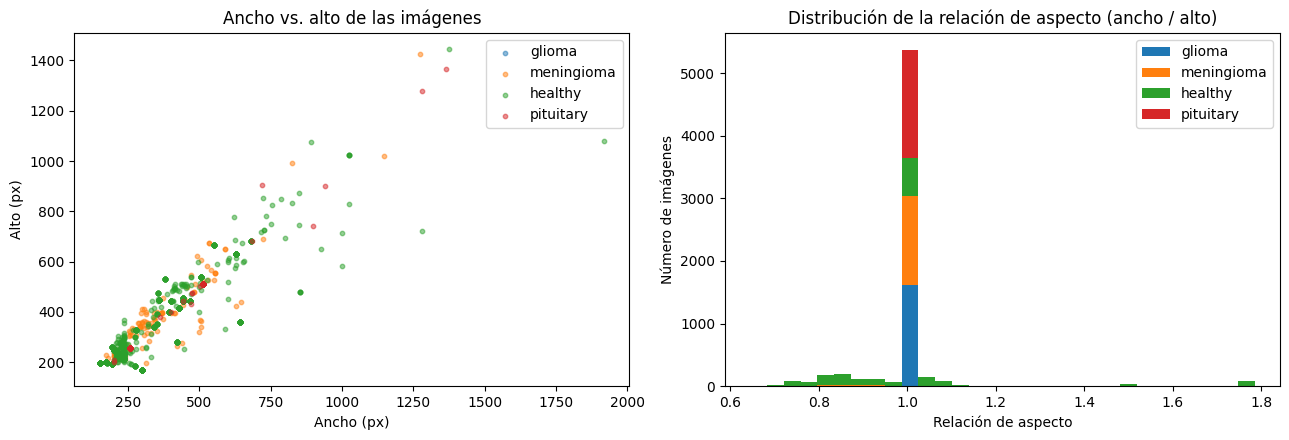

In [5]:
# Inspección de dimensiones espaciales y modos de color de los cortes de MRI
def read_image_metadata(filepath: str) -> dict:
    # Image.open solo lee la cabecera del archivo, sin decodificar los píxeles
    with Image.open(filepath) as img:
        return {"width": img.width, "height": img.height, "mode": img.mode}

df_meta = pd.concat([df_clean, pd.DataFrame(df_clean["filepath"].map(read_image_metadata).tolist())], axis=1)
df_meta["aspect_ratio"] = df_meta["width"] / df_meta["height"]

print(f"Resoluciones distintas: {df_meta.groupby(['width', 'height']).ngroups}")
print(f"Imágenes cuadradas: {(df_meta['width'] == df_meta['height']).mean() * 100:.2f} %")
print("\nModos de color:")
display(pd.crosstab(df_meta["label_name"], df_meta["mode"]).reindex(CLASSES))

print("Estadísticos de dimensiones por categoría:")
display(df_meta.groupby("label_name")[["width", "height"]]
        .agg(["min", "median", "max"]).reindex(CLASSES))

print("Resoluciones más frecuentes:")
display(df_meta.value_counts(["width", "height"]).head(10).rename("frecuencia").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for cls_name in CLASSES:
    subset = df_meta[df_meta["label_name"] == cls_name]
    axes[0].scatter(subset["width"], subset["height"], s=10, alpha=0.5, label=cls_name)
axes[0].set_title("Ancho vs. alto de las imágenes")
axes[0].set_xlabel("Ancho (px)")
axes[0].set_ylabel("Alto (px)")
axes[0].legend()

axes[1].hist([df_meta.loc[df_meta["label_name"] == c, "aspect_ratio"] for c in CLASSES],
             bins=30, stacked=True, label=CLASSES)
axes[1].set_title("Distribución de la relación de aspecto (ancho / alto)")
axes[1].set_xlabel("Relación de aspecto")
axes[1].set_ylabel("Número de imágenes")
axes[1].legend()
plt.tight_layout()
plt.show()

#### 1.2.4. Cuantificación de imágenes pequeñas y no cuadradas por categoría
Tomando como referencia el tamaño de entrada objetivo de 224 px, se cuenta por categoría cuántas imágenes tienen el lado menor o ambos lados por debajo de ese tamaño (y, por tanto, requerirían ampliarse) y cuántas se apartan del formato cuadrado (relación de aspecto mayor a 1.1 y a 1.3). Estas cifras sustentan la elección del tamaño de entrada y del relleno a formato cuadrado en el *pipeline* de transformaciones (1.4).

In [6]:
# Cuantificación de imágenes pequeñas y no cuadradas por categoría
TARGET_SIZE = 224
df_meta["min_side"] = df_meta[["width", "height"]].min(axis=1)
df_meta["max_side"] = df_meta[["width", "height"]].max(axis=1)
df_meta["max_aspect"] = df_meta["max_side"] / df_meta["min_side"]

df_size_issues = df_meta.groupby("label_name").agg(
    total=("filepath", "size"),
    lado_menor_bajo_objetivo=("min_side", lambda s: (s < TARGET_SIZE).sum()),
    ambos_lados_bajo_objetivo=("max_side", lambda s: (s < TARGET_SIZE).sum()),
    aspecto_mayor_1_1=("max_aspect", lambda s: (s > 1.1).sum()),
    aspecto_mayor_1_3=("max_aspect", lambda s: (s > 1.3).sum()),
).reindex(CLASSES)
display(df_size_issues)

,total,lado_menor_bajo_objetivo,ambos_lados_bajo_objetivo,aspecto_mayor_1_1,aspecto_mayor_1_3
label_name,,,,,
glioma,1620,0,0,0,0
meningioma,1531,45,8,76,13
healthy,1706,725,130,720,215
pituitary,1740,2,2,2,0


#### 1.2.5. Visualización de una muestra representativa de cortes de MRI por categoría
Se seleccionan aleatoriamente, con semilla fija para garantizar la reproducibilidad, cinco imágenes por categoría y se muestran en escala de grises junto con su resolución original. La inspección permite reconocer los planos anatómicos y las secuencias de adquisición presentes, así como posibles diferencias visuales entre clases ajenas a la patología.

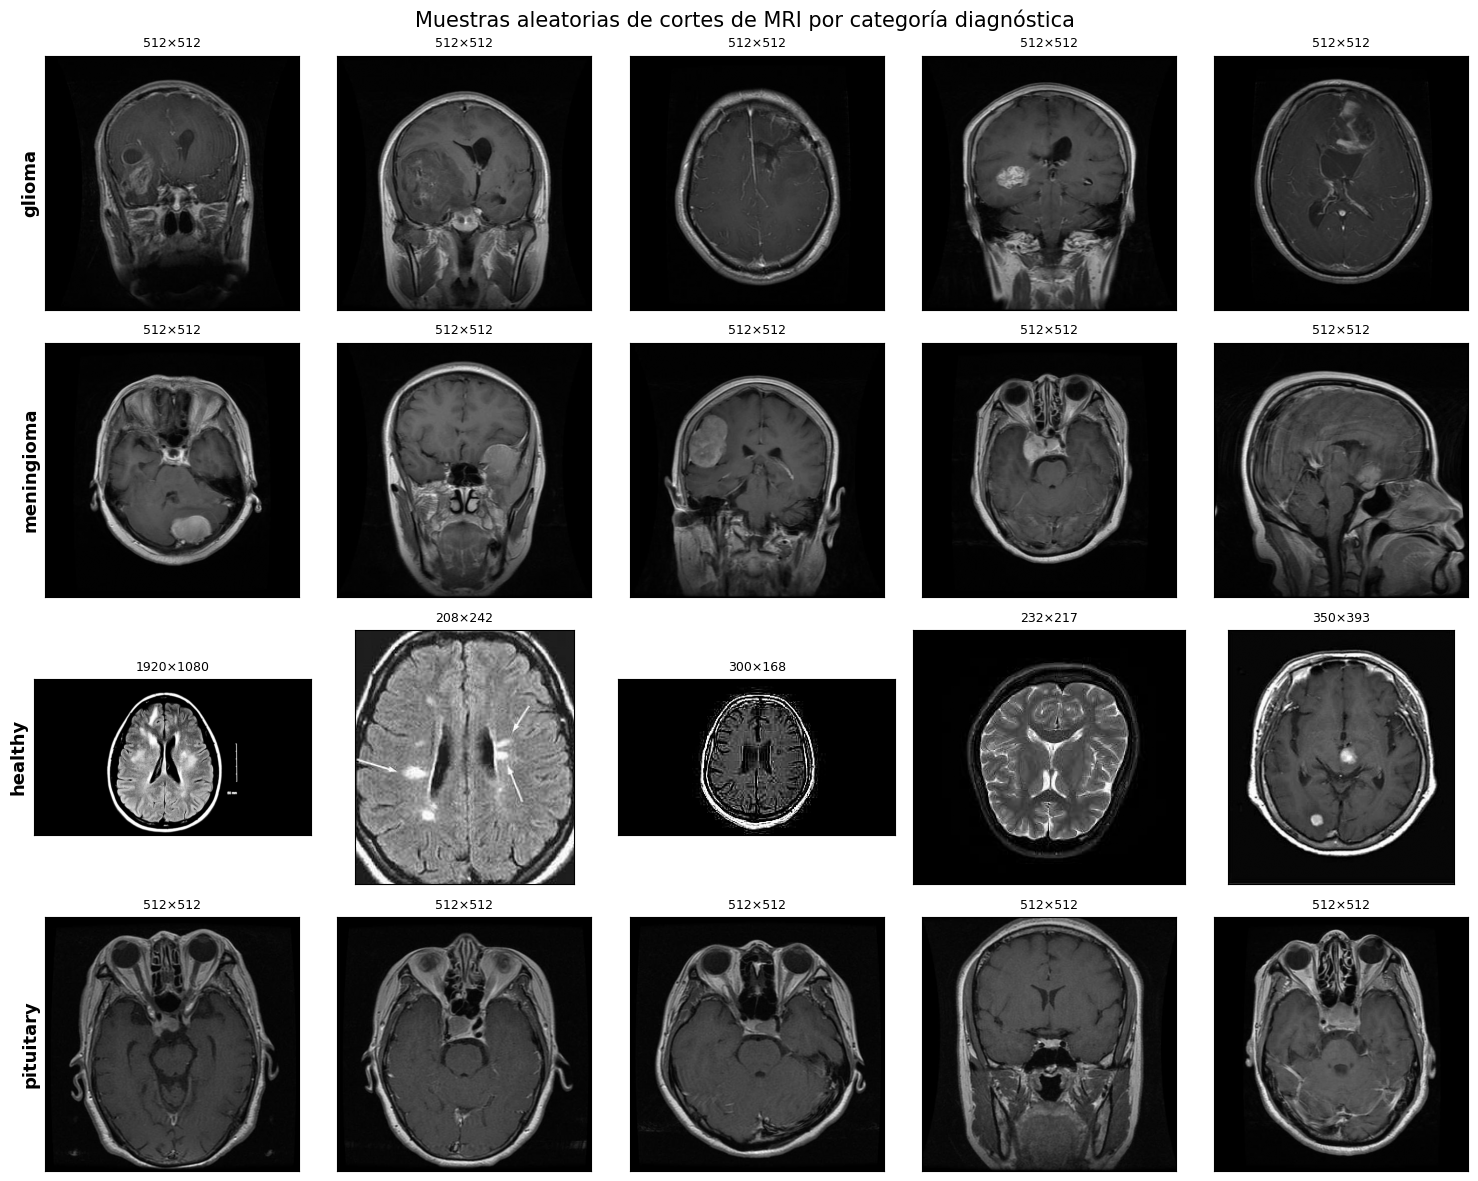

In [7]:
# Visualización de una muestra representativa de cortes de MRI por categoría
N_SAMPLES_PER_CLASS = 5
rng = np.random.default_rng(42)

fig, axes = plt.subplots(len(CLASSES), N_SAMPLES_PER_CLASS, figsize=(3 * N_SAMPLES_PER_CLASS, 3 * len(CLASSES)))
for row, cls_name in enumerate(CLASSES):
    subset = df_meta[df_meta["label_name"] == cls_name]
    sample_idx = rng.choice(subset.index, size=N_SAMPLES_PER_CLASS, replace=False)
    for col, idx in enumerate(sample_idx):
        record = df_meta.loc[idx]
        with Image.open(record["filepath"]) as img:
            axes[row, col].imshow(img.convert("L"), cmap="gray")
        axes[row, col].set_title(f"{record['width']}×{record['height']}", fontsize=9)
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
    axes[row, 0].set_ylabel(cls_name, fontsize=13, fontweight="bold")
fig.suptitle("Muestras aleatorias de cortes de MRI por categoría diagnóstica", fontsize=15)
plt.tight_layout()
plt.show()

#### 1.2.6. Detección de marcos claros en el borde de las imágenes
Durante la inspección visual se observó que algunas imágenes incluyen un marco claro de pocos píxeles en su borde, ajeno a la anatomía. Para cuantificarlo, se analizan las 3 líneas exteriores de cada lado y se considera claro un lado cuando la mediana de su intensidad máxima supera 80 (escala 0–255). Las imágenes se clasifican en: sin borde claro, borde parcial (1 a 3 lados) y marco completo (4 lados). El borde parcial puede deberse tanto a marcos incompletos como a anatomía que toca el borde (p. ej. cuello o cráneo en cortes ajustados), mientras que el marco completo corresponde inequívocamente a un artefacto de origen. Se muestran ejemplos de imágenes con marco completo.

In [ ]:
# Detección de marcos claros en el borde de las imágenes por categoría
EDGE_WIDTH = 3        # líneas exteriores analizadas en cada lado (px)
EDGE_INTENSITY = 80   # intensidad a partir de la cual un lado se considera claro (escala 0-255)

def count_bright_sides(filepath: str) -> int:
    # Un lado es claro si la mediana, a lo largo del lado, del máximo de sus líneas exteriores supera EDGE_INTENSITY
    with Image.open(filepath) as img:
        gray = np.asarray(img.convert("L"))
    edges = [gray[:EDGE_WIDTH].max(axis=0), gray[-EDGE_WIDTH:].max(axis=0),
             gray[:, :EDGE_WIDTH].max(axis=1), gray[:, -EDGE_WIDTH:].max(axis=1)]
    return sum(np.median(edge) > EDGE_INTENSITY for edge in edges)

df_meta["bright_sides"] = df_meta["filepath"].map(count_bright_sides)
df_meta["frame_type"] = pd.cut(df_meta["bright_sides"], bins=[-1, 0, 3, 4],
                               labels=["sin_borde_claro", "borde_parcial_1_3_lados", "marco_completo_4_lados"])

frame_counts = pd.crosstab(df_meta["label_name"], df_meta["frame_type"]).reindex(CLASSES)
total = frame_counts.sum(axis=1)
df_frames = frame_counts.assign(**{
    "con_borde_claro_%": ((total - frame_counts["sin_borde_claro"]) / total * 100).round(2),
    "marco_completo_%": (frame_counts["marco_completo_4_lados"] / total * 100).round(2),
})
display(df_frames)

framed = df_meta[df_meta["bright_sides"] == 4]
examples = framed.groupby("label_name", observed=True).head(2).head(6)
fig, axes = plt.subplots(1, len(examples), figsize=(3 * len(examples), 3.4), squeeze=False)
for ax, (_, record) in zip(axes[0], examples.iterrows()):
    with Image.open(record["filepath"]) as img:
        ax.imshow(img.convert("L"), cmap="gray")
    ax.set_title(f"{record['label_name']} ({record['width']}×{record['height']})", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Ejemplos de imágenes con marco claro completo en el borde", fontsize=13)
plt.tight_layout()
plt.show()

#### 1.2.7. Hallazgos del EDA

Todas las cifras corresponden al conjunto depurado ($6\,597$ imágenes únicas).

- **Imágenes duplicadas:** de las $7\,023$ imágenes originales se identificaron 300 grupos de imágenes idénticas (hash MD5) que suman 426 copias redundantes, concentradas en `healthy` (294) y `meningioma` (114). Ninguna copia aparece con etiquetas distintas. Se conserva una sola imagen por grupo antes de cualquier análisis o partición, evitando que copias de una misma imagen sesguen las estadísticas o queden simultáneamente en entrenamiento y prueba (*data leakage*). El hash solo detecta copias exactas: imágenes casi idénticas (reescaladas o recomprimidas) o cortes contiguos de un mismo paciente podrían persistir, y el conjunto no incluye un identificador de paciente que permita controlarlo.
- **Balance de clases:** la distribución es prácticamente balanceada: `pituitary` es la clase mayoritaria (1 740 imágenes, 26.4 %) y `meningioma` la minoritaria (1 531, 23.2 %), con una razón de desbalance de 1.14. No se requieren técnicas agresivas de rebalanceo, aunque se usará partición estratificada, pesos por clase en la función de pérdida y se reportará el *Macro F1-Score* para no favorecer a ninguna categoría.
- **Dimensiones espaciales heterogéneas:** existen 387 resoluciones distintas (de 150 px hasta 1 920 px de lado) y el 80.1 % de las imágenes son cuadradas. Las imágenes pequeñas y no cuadradas se concentran casi exclusivamente en `healthy` (725 con lado menor < 224 px y 720 con relación de aspecto > 1.1) y, en menor medida, en `meningioma` (45 y 76); `glioma` y `pituitary` son prácticamente todas de 512×512 px.
- **Resolución correlacionada con la clase:** el 100 % de `glioma`, el 97.5 % de `pituitary` y el 90.4 % de `meningioma` miden 512×512 px, mientras que solo el 0.9 % de `healthy` tiene esa resolución (mediana ≈ 228×242 px). Esta diferencia de origen puede inducir un **atajo** (*shortcut learning*): la red podría distinguir `healthy` por artefactos de reescalado o nitidez en lugar de por la anatomía. Para mitigarlo, se opta por **reducir** todas las imágenes a 224×224 px en lugar de ampliarlas a 512×512 px: ampliar `healthy` no agrega información y la suavizaría por interpolación. El redimensionamiento común elimina la diferencia de tamaño, pero no necesariamente la de nitidez, ya que las imágenes de 512 px se reducen ≈ 2.2 veces mientras que las de `healthy` quedan cerca de su resolución original; para atenuar este efecto se incorpora un desenfoque gaussiano aleatorio en el aumento de datos de entrenamiento (sección 1.4). Las imágenes no cuadradas se **rellenan con ceros** hasta hacerlas cuadradas antes de redimensionar, evitando tanto la deformación anatómica (escalar una sola dimensión) como la pérdida de contenido (recorte central).
- **Marcos claros en el borde:** el 2.81 % de las imágenes de `healthy` presenta un marco claro completo en sus 4 lados y el 14.30 % algún borde claro, frente a 0.33 % y 2.68 % en `meningioma`, 0.17 % y 0.34 % en `pituitary` y ninguna en `glioma`. Al concentrarse en `healthy`, el marco constituye otro posible **atajo** para identificar la clase y, al rotar con el aumento de datos, delataría la orientación original de la imagen. Por ello, el *pipeline* de transformaciones (1.4) recorta cada imagen a su contenido anatómico antes del relleno y el redimensionamiento, eliminando el marco y los márgenes negros.
- **Modo de color:** todas las imágenes están almacenadas en RGB, pero corresponden a cortes en escala de grises (canales redundantes); pueden convertirse a 1 canal para un modelo propio o mantener 3 canales para reutilizar redes preentrenadas.
- **Inspección visual:** las muestras incluyen planos axiales, coronales y sagitales, así como distintas secuencias de adquisición (T1 con contraste, T2, FLAIR), lo que aporta variabilidad deseable pero también aumenta la dificultad de la tarea. No se separan los planos, ya que el conjunto no incluye esa etiqueta y un clasificador útil debe reconocer la patología en cualquier corte. Sin embargo, la proporción de planos no parece uniforme entre clases (p. ej. `healthy` muestra mayoritariamente cortes axiales), lo que constituye un posible factor de confusión que se revisará en el análisis cualitativo (3.3).

### 1.3. Partición en Conjuntos de Entrenamiento, Validación y Prueba
El conjunto de datos depurado (sin duplicados) se divide de forma estratificada en los subconjuntos de entrenamiento (`Train`, 70 %), validación (`Val`, 15 %) y prueba (`Test`, 15 %), preservando las proporciones originales de cada categoría y evitando la fuga de información (*data leakage*) entre particiones. Se verifica que ninguna imagen aparezca en más de una partición. Adicionalmente, se calculan pesos por clase inversamente proporcionales a su frecuencia en `Train` ($w_c = N / (C \cdot n_c)$) para ponderar la función de pérdida (sección 2.2), de modo que todas las categorías contribuyan por igual al gradiente. Esta etapa solo reparte rutas y etiquetas; el aumento de datos se aplica en la sección 1.4, exclusivamente sobre `Train`.

In [8]:
# Partición estratificada en conjuntos de entrenamiento, validación y prueba
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
VAL_SIZE = 0.15
TEST_SIZE = 0.15

df_train_val, df_test = train_test_split(
    df_clean, test_size=TEST_SIZE, stratify=df_clean["label"], random_state=RANDOM_STATE)
df_train, df_val = train_test_split(
    df_train_val, test_size=VAL_SIZE / (1 - TEST_SIZE), stratify=df_train_val["label"], random_state=RANDOM_STATE)
df_train, df_val, df_test = (df.reset_index(drop=True) for df in (df_train, df_val, df_test))

# Verificación de ausencia de fuga de información entre particiones
splits = {"Train": df_train, "Val": df_val, "Test": df_test}
assert set(df_train["md5"]).isdisjoint(df_val["md5"])
assert set(df_train["md5"]).isdisjoint(df_test["md5"])
assert set(df_val["md5"]).isdisjoint(df_test["md5"])

split_counts = pd.DataFrame({name: df["label_name"].value_counts() for name, df in splits.items()}).reindex(CLASSES)
split_pct = (split_counts / split_counts.sum() * 100).round(2).add_suffix("_%")
df_split_summary = pd.concat([split_counts, split_pct], axis=1)
display(df_split_summary)
print(" | ".join(f"{name}: {len(df)} ({len(df) / len(df_clean) * 100:.1f} %)" for name, df in splits.items()))

# Pesos por clase inversamente proporcionales a su frecuencia en Train, para ponderar la función de pérdida (sección 2.2)
train_counts = df_train["label"].value_counts().sort_index()
CLASS_WEIGHTS = (len(df_train) / (len(CLASSES) * train_counts)).to_numpy(dtype="float32")
display(pd.DataFrame({"imagenes_train": train_counts.to_numpy(), "peso": CLASS_WEIGHTS.round(4)}, index=CLASSES))

,Train,Val,Test,Train_%,Val_%,Test_%
label_name,,,,,,
glioma,1134,243,243,24.56,24.55,24.55
meningioma,1071,230,230,23.20,23.23,23.23
healthy,1194,256,256,25.86,25.86,25.86
pituitary,1218,261,261,26.38,26.36,26.36


Train: 4617 (70.0 %) | Val: 990 (15.0 %) | Test: 990 (15.0 %)


,imagenes_train,peso
glioma,1134,1.0179
meningioma,1071,1.0777
healthy,1194,0.9667
pituitary,1218,0.9477


### 1.4. Pipeline de Transformaciones, `Dataset` y `DataLoaders`
Se establecen las transformaciones de estandarización espacial (recorte al contenido anatómico, relleno con ceros a formato cuadrado y reducción a 224×224 px), conversión a tensor y normalización de intensidad. El recorte al contenido elimina los márgenes negros y los marcos claros presentes en el borde de algunas imágenes, principalmente de `healthy`; de no eliminarse, estos marcos podrían convertirse en un atajo para identificar la clase y, al rotar con el aumento de datos, delatarían la orientación original de la imagen. Además, homogeniza la proporción del cuadro ocupada por el cerebro entre las distintas fuentes. Para el subconjunto de entrenamiento se incorporan técnicas de aumento de datos (*Data Augmentation*) que preservan la etiqueta y corresponden a variaciones reales de la adquisición: volteo horizontal, rotaciones (±10°) y traslaciones (±5 %) leves con relleno negro, variación de brillo y contraste y desenfoque gaussiano aleatorio. Su propósito no es corregir el desbalance (que es leve y se controla con el *Macro F1-Score*), sino reducir el sobreajuste: las transformaciones geométricas favorecen la invariancia a la posición, las variaciones de intensidad simulan diferencias entre equipos y secuencias, y el desenfoque aleatorio atenúa el atajo por nitidez identificado en el EDA. La diferencia de tamaño entre clases se resuelve con el redimensionamiento común, no con el aumento. Se descarta el volteo vertical por producir anatomía no plausible. El aumento se aplica únicamente al conjunto de entrenamiento; validación y prueba usan solo las transformaciones de estandarización para no sesgar las métricas. Posteriormente, se instancian las estructuras `Dataset` y `DataLoader` para el suministro eficiente por lotes (*batches*).

#### 1.4.1. Definición de transformaciones, clase Dataset y generadores DataLoader
Se implementan dos transformaciones propias: `CropToContent`, que recorta cada imagen a su contenido anatómico descartando márgenes negros y marcos claros del borde, y `PadToSquare`, que rellena con ceros el lado menor hasta obtener un formato cuadrado. A partir de ellas se componen dos *pipelines*: uno de evaluación (recorte, relleno, redimensionamiento a 224×224 px, conversión a tensor y normalización con las estadísticas de ImageNet) y uno de entrenamiento, que añade el aumento de datos. Finalmente, la clase `BrainMRIDataset` carga cada imagen bajo demanda a partir de su ruta y aplica el *pipeline* correspondiente, y se crean los `DataLoader` de cada partición; solo el de entrenamiento baraja las muestras. Se verifica la forma de un lote para confirmar que los tensores tienen las dimensiones esperadas.

In [9]:
# Definición de transformaciones, clase Dataset y generadores DataLoader
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torchvision.transforms.functional as TF

IMG_SIZE = 224
BATCH_SIZE = 32
# En Jupyter sobre macOS/Windows, num_workers > 0 falla con clases definidas en el notebook
NUM_WORKERS = 0
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

class CropToContent:
    # Recorta la imagen al contenido anatómico, descartando márgenes negros y marcos claros del borde.
    # 1) Se eliminan las bandas claras que cruzan toda la imagen pegadas a cada borde (hasta `max_band` del lado).
    # 2) Una fila/columna es contenido si al menos `min_fraction` de sus píxeles supera `threshold`,
    #    por lo que las líneas finas de un marco no amplían el recorte.
    def __init__(self, threshold: int = 20, min_fraction: float = 0.02, band_fraction: float = 0.95,
                 max_band: float = 0.05, border: int = 3, margin: int = 4):
        self.threshold = threshold
        self.min_fraction = min_fraction
        self.band_fraction = band_fraction
        self.max_band = max_band
        self.border = border
        self.margin = margin

    def _content_range(self, fraction: np.ndarray) -> tuple:
        n = len(fraction)
        start, end = self.border, n - self.border
        limit = int(self.max_band * n)
        while start < limit and fraction[start] >= self.band_fraction:
            start += 1
        while end > n - limit and fraction[end - 1] >= self.band_fraction:
            end -= 1
        idx = start + np.flatnonzero(fraction[start:end] > self.min_fraction)
        if idx.size == 0:
            return 0, n
        return max(idx[0] - self.margin, start), min(idx[-1] + self.margin + 1, end)

    def __call__(self, img: Image.Image) -> Image.Image:
        mask = np.asarray(img.convert("L")) > self.threshold
        top, bottom = self._content_range(mask.mean(axis=1))
        left, right = self._content_range(mask.mean(axis=0))
        return img.crop((left, top, right, bottom))

class PadToSquare:
    # Rellena con ceros (fondo negro) el lado menor para evitar deformar o recortar la anatomía
    def __call__(self, img: Image.Image) -> Image.Image:
        w, h = img.size
        side = max(w, h)
        left, top = (side - w) // 2, (side - h) // 2
        return TF.pad(img, [left, top, side - w - left, side - h - top], fill=0)

base_transform = [CropToContent(), PadToSquare(), transforms.Resize((IMG_SIZE, IMG_SIZE), antialias=True)]
tensor_transform = [transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)]

# El aumento de datos se aplica únicamente al conjunto de entrenamiento
train_transform = transforms.Compose(base_transform + [
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(degrees=10, translate=(0.05, 0.05), fill=0),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.RandomApply([transforms.GaussianBlur(kernel_size=3)], p=0.3),
] + tensor_transform)

eval_transform = transforms.Compose(base_transform + tensor_transform)

class BrainMRIDataset(Dataset):
    def __init__(self, df: pd.DataFrame, transform=None):
        self.filepaths = df["filepath"].tolist()
        self.labels = df["label"].tolist()
        self.transform = transform

    def __len__(self) -> int:
        return len(self.filepaths)

    def __getitem__(self, idx: int):
        with Image.open(self.filepaths[idx]) as img:
            img = img.convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, self.labels[idx]

train_dataset = BrainMRIDataset(df_train, train_transform)
val_dataset = BrainMRIDataset(df_val, eval_transform)
test_dataset = BrainMRIDataset(df_test, eval_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

print(f"Lotes — Train: {len(train_loader)} | Val: {len(val_loader)} | Test: {len(test_loader)}")
images, labels = next(iter(train_loader))
print(f"Forma de un lote: {tuple(images.shape)} | Etiquetas: {tuple(labels.shape)}")

Lotes — Train: 145 | Val: 31 | Test: 31
Forma de un lote: (32, 3, 224, 224) | Etiquetas: (32,)


#### 1.4.2. Verificación visual del pipeline de transformaciones sobre una imagen no cuadrada
Se selecciona una imagen no cuadrada del conjunto y se muestra junto con su versión estandarizada (*pipeline* de validación y prueba) y cuatro variantes generadas por el *pipeline* de entrenamiento, con semilla fija para reproducibilidad. Esta inspección permite comprobar que el recorte elimina márgenes y marcos sin perder anatomía, que el relleno conserva la proporción original y que el aumento de datos produce variaciones plausibles sin introducir artefactos.

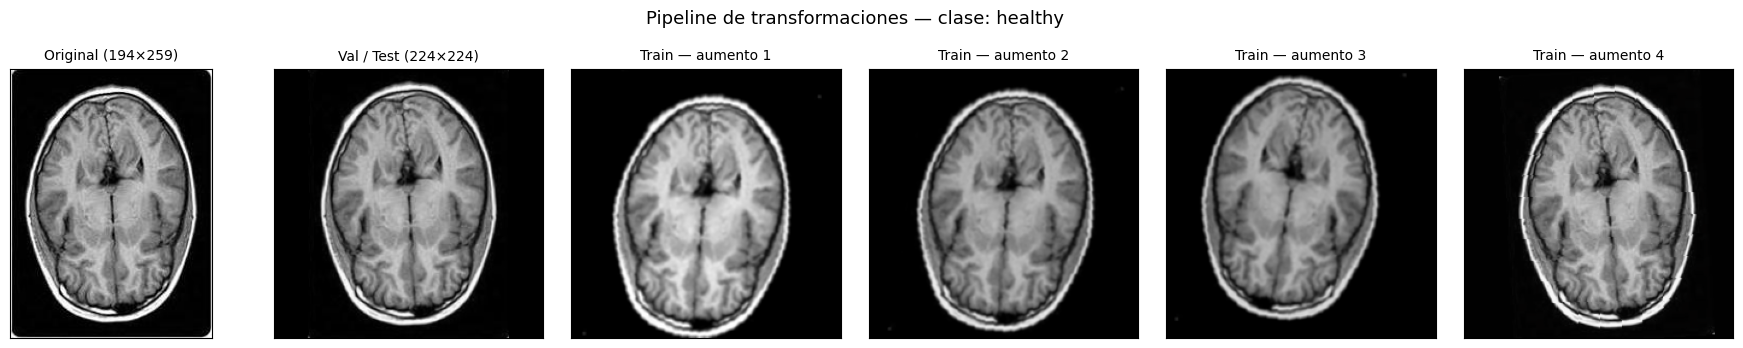

In [10]:
# Verificación visual del pipeline de transformaciones sobre una imagen no cuadrada
N_AUGMENTED = 4
torch.manual_seed(42)

sample_record = df_meta[df_meta["max_aspect"] > 1.3].iloc[0]
with Image.open(sample_record["filepath"]) as img:
    sample_img = img.convert("RGB")

def denormalize(tensor: torch.Tensor) -> np.ndarray:
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (tensor * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

fig, axes = plt.subplots(1, N_AUGMENTED + 2, figsize=(3 * (N_AUGMENTED + 2), 3.5))
axes[0].imshow(sample_img)
axes[0].set_title(f"Original ({sample_img.width}×{sample_img.height})", fontsize=10)
axes[1].imshow(denormalize(eval_transform(sample_img)))
axes[1].set_title(f"Val / Test ({IMG_SIZE}×{IMG_SIZE})", fontsize=10)
for k in range(N_AUGMENTED):
    axes[k + 2].imshow(denormalize(train_transform(sample_img)))
    axes[k + 2].set_title(f"Train — aumento {k + 1}", fontsize=10)
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle(f"Pipeline de transformaciones — clase: {sample_record['label_name']}", fontsize=13)
plt.tight_layout()
plt.show()

---
## 2. Desarrollo de la Arquitectura de Red Neuronal Convolucional (CNN)
En esta sección se formula e implementa la arquitectura de red neuronal convolucional orientada a la clasificación de los cortes de MRI en las 4 categorías de estudio, contemplando el uso de bloques convolucionales con reducción espacial (*Max Pooling*) o esquemas de transferencia de aprendizaje (*fine-tuning*) sobre redes preentrenadas.

### 2.1. Definición de la Arquitectura del Modelo
Se construye el modelo convolucional definiendo las capas de extracción de características, los mecanismos de normalización y regularización (`BatchNorm2d`, `Dropout`) y el cabezal de clasificación con dimensión de salida $C = 4$.

In [11]:
# Definición e instanciación de la arquitectura de red neuronal convolucional


### 2.2. Configuración de Función de Pérdida, Optimizador y Ciclo de Entrenamiento
Se especifican la función de pérdida de entropía cruzada multiclase, el algoritmo de optimización, el planificador de tasa de aprendizaje y las rutinas modulares encargadas de ejecutar cada época de entrenamiento y evaluación sobre el conjunto de validación.

In [12]:
# Funciones modulares de entrenamiento por época, evaluación y ajuste del modelo


### 2.3. Ejecución del Entrenamiento y Registro de Métricas
Se ejecuta el proceso de optimización del modelo a lo largo de las épocas establecidas, monitoreando la pérdida y el desempeño en entrenamiento y validación, y conservando los pesos asociados al mejor estado de generalización.

In [13]:
# Ejecución del entrenamiento y almacenamiento del historial de métricas


---
## 3. Evaluación del Modelo y Análisis de Resultados

### 3.1. Curvas de Aprendizaje
Se grafica la evolución temporal de la función de pérdida y la exactitud (*Accuracy* / *F1-Score*) en los subconjuntos de entrenamiento y validación con el objetivo de analizar la estabilidad de la convergencia y diagnosticar posibles comportamientos de subajuste (*underfitting*) o sobreajuste (*overfitting*).

In [14]:
# Visualización de curvas de pérdida y exactitud durante el entrenamiento


### 3.2. Desempeño Cuantitativo en el Conjunto de Prueba (`Test`)
Se evalúa la capacidad de generalización del modelo final sobre el conjunto de prueba independiente, reportando la exactitud global (*Accuracy*), precisión (*Precision*), sensibilidad (*Recall*), *Macro F1-Score* desagregado por categoría y la matriz de confusión correspondiente.

In [15]:
# Evaluación cuantitativa en el conjunto de prueba y generación de matriz de confusión


### 3.3. Análisis Cualitativo de Predicciones
Se presenta una inspección visual sobre muestras del conjunto de prueba contrastando la etiqueta clínica real frente a la predicción asignada por la red, incluyendo tanto aciertos como casos de confusión entre patologías.

In [16]:
# Visualización cualitativa de predicciones correctas y errores de clasificación


---
## 4. Discusión y Conclusiones
- **Síntesis de resultados:** 
- **Análisis por categoría tumoral:** 
- **Limitaciones y trabajo futuro:** 